Explanatory Data Analysis

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

DATA = Path("C:/Users/lydia/Research-SWE/LUNA-Analysis/data")                      
IMG_DIR = DATA / "CT" / "CT" / "image"
MASK_DIR = DATA / "CT" / "CT" / "nodule_mask"  

scan_files = sorted(IMG_DIR.glob("*.nii.gz"))
print(f"{len(scan_files)} scans found")

3 scans found


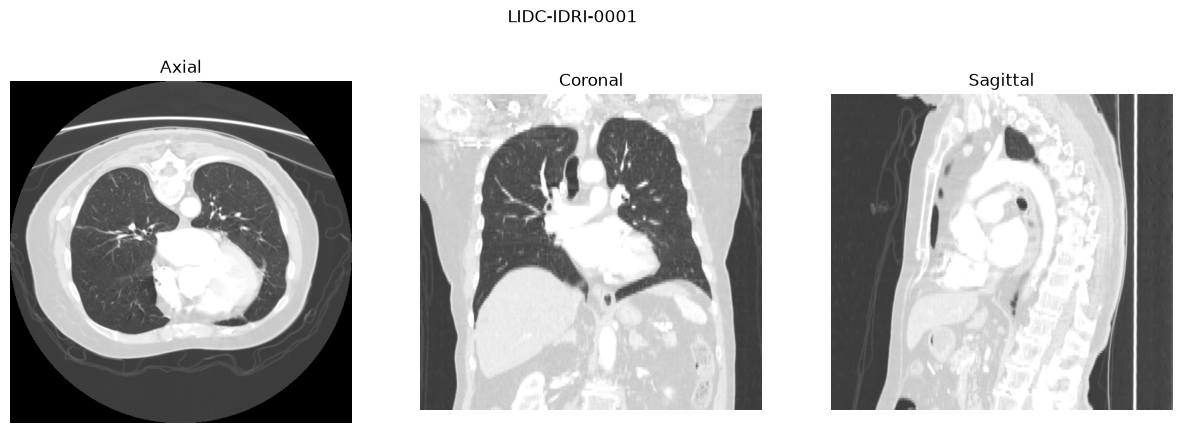

In [ ]:
def load_scan(path):
    img = nib.load(path)
    vol = np.asanyarray(img.dataobj).astype(np.float32)   
    return img, vol

def show_three_views(path, window=(-1400, 200)):
    img, vol = load_scan(path)
    sx, sy, sz = img.header.get_zooms()[:3]
    x, y, z = (s // 2 for s in vol.shape)
    kw = dict(cmap="gray", vmin=window[0], vmax=window[1], origin="lower")

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(vol[:, :, z].T, aspect=sy / sx, **kw); ax[0].set_title("Axial")
    ax[1].imshow(vol[:, y, :].T, aspect=sz / sx, **kw); ax[1].set_title("Coronal")
    ax[2].imshow(vol[x, :, :].T, aspect=sz / sy, **kw); ax[2].set_title("Sagittal")
    for a in ax: a.axis("off")
    fig.suptitle(path.name.replace(".nii.gz", ""))
    plt.show()

show_three_views(scan_files[0])

In [ ]:
rows = []
for p in scan_files:
    img = nib.load(p)
    sx, sy, sz = img.header.get_zooms()[:3]
    rows.append({
        "patient_id": p.name.replace(".nii.gz", ""),
        "shape": img.shape,
        "n_slices": img.shape[2],
        "sx": sx, "sy": sy, "sz": sz,
        "orientation": "".join(nib.aff2axcodes(img.affine)),
    })
inv = pd.DataFrame(rows)
print(inv.describe())
print(inv["orientation"].value_counts())    # are all scans in the same orientation?
inv.to_csv("C:/Users/lydia/Research-SWE/LUNA-Analysis/data/processedscan_inventory.csv", index=False)

         n_slices        sx        sy   sz
count    3.000000  3.000000  3.000000  3.0
mean   135.333333  0.729166  0.729166  2.5
std      4.041452  0.081315  0.081315  0.0
min    133.000000  0.664062  0.664062  2.5
25%    133.000000  0.683594  0.683594  2.5
50%    133.000000  0.703125  0.703125  2.5
75%    136.500000  0.761719  0.761719  2.5
max    140.000000  0.820312  0.820312  2.5
orientation
LPS    3
Name: count, dtype: int64


In [24]:
# --- Cell 4: the Excel file (you only printed head() so far) ---
df = pd.read_excel(DATA / "MetadatabyAnnotation.xlsx")
print(df.shape)
print(df.columns.tolist())
df.info()
df.isna().sum()

(3674, 33)
['patient_id', 'nodule_id', 'seriesuid', 'coordX', 'coordY', 'coordZ', 'diameter_mm', 'bboxLowX', 'bboxLowY', 'bboxLowZ', 'bboxHighX', 'bboxHighY', 'bboxHighZ', 'Malignancy', 'Malignancy_value', 'anotation_id', 'Calcification', 'Calcification_value', 'InternalStructure', 'InternalStructure_value', 'Lobulation', 'Lobulation_value', 'Margin', 'Margin_value', 'Sphericity', 'Sphericity_value', 'Spiculation', 'Spiculation_value', 'Subtlety', 'Subtlety_value', 'Texture', 'Texture_value', 'len_mal_details']
<class 'pandas.DataFrame'>
RangeIndex: 3674 entries, 0 to 3673
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               3674 non-null   str    
 1   nodule_id                3674 non-null   int64  
 2   seriesuid                3674 non-null   str    
 3   coordX                   3674 non-null   float64
 4   coordY                   3674 non-null   float64
 5   coor

patient_id                 0
nodule_id                  0
seriesuid                  0
coordX                     0
coordY                     0
coordZ                     0
diameter_mm                0
bboxLowX                   0
bboxLowY                   0
bboxLowZ                   0
bboxHighX                  0
bboxHighY                  0
bboxHighZ                  0
Malignancy                 0
Malignancy_value           0
anotation_id               0
Calcification              0
Calcification_value        0
InternalStructure          0
InternalStructure_value    0
Lobulation                 0
Lobulation_value           0
Margin                     0
Margin_value               0
Sphericity                 0
Sphericity_value           0
Spiculation                0
Spiculation_value          0
Subtlety                   0
Subtlety_value             0
Texture                    0
Texture_value              0
len_mal_details            0
dtype: int64

In [27]:
pid = df["patient_id"].iloc[0]
print(repr(pid), df["patient_id"].dtype)

cols = ["patient_id", "nodule_id", "anotation_id", "Malignancy",
        "Malignancy_value", "len_mal_details", "coordX", "diameter_mm"]
df[df["patient_id"] == pid][cols]      # all rows for the first patient

# are coordinates identical across annotations of the same nodule?
print(df.groupby(["patient_id", "nodule_id"])["coordX"].nunique().value_counts())
print(df.groupby(["patient_id", "nodule_id"]).size().value_counts())

'LIDC-IDRI-0001' str
coordX
1    995
2      1
Name: count, dtype: int64
4    667
3    323
5      3
6      1
9      1
7      1
Name: count, dtype: int64


In [28]:
import ast

def parse_ratings(v):
    """Return a list of ints whether v is a number or a string like '[5, 5, 5, 4]'."""
    if isinstance(v, str):
        return [int(r) for r in ast.literal_eval(v)]
    return [int(v)]

def is_malignant(ratings):
    return int(sum(r > 3 for r in ratings) >= 2)

# Test cases from the PDF (nodule 1 of LIDC-IDRI-0001 and LIDC-IDRI-0004)
assert is_malignant([5, 5, 5, 4]) == 1
assert is_malignant([2, 1, 1, 1]) == 0

In [29]:
nod = (df.groupby(["patient_id", "nodule_id"])
         .agg(ratings=("Malignancy_value", list),
              n_annotations=("anotation_id", "nunique"),
              diameter_mm=("diameter_mm", "mean"))
         .reset_index())
nod["malignant"] = nod["ratings"].apply(is_malignant)
print(nod["malignant"].value_counts())
print(nod["n_annotations"].value_counts())   # how many nodules have only 1 annotator?

malignant
0    650
1    346
Name: count, dtype: int64
n_annotations
4    667
3    323
5      3
6      1
9      1
7      1
Name: count, dtype: int64


In [30]:
import numpy as np

row = df[df["patient_id"] == "LIDC-IDRI-0001"].iloc[0]   # adjust to your ID format
img = nib.load(IMG_DIR / "LIDC-IDRI-0001.nii.gz")
inv_aff = np.linalg.inv(img.affine)

x, y, z = row["coordX"], row["coordY"], row["coordZ"]
for label, pt in [("as given", (x, y, z)), ("flip x,y", (-x, -y, z))]:
    ijk = (inv_aff @ np.array([*pt, 1]))[:3]
    print(label, np.round(ijk, 1), "inside volume:",
          all(0 <= v < s for v, s in zip(ijk, img.shape)))

as given [156.1 121.4  89.7] inside volume: True
flip x,y [316.  367.   89.7] inside volume: True


In [31]:
counts = df.groupby(["patient_id", "nodule_id"]).size()
odd = counts[counts > 4].index.tolist()

n_coord = df.groupby(["patient_id", "nodule_id"])["coordX"].nunique()
odd += n_coord[n_coord > 1].index.tolist()

cols = ["patient_id", "nodule_id", "anotation_id", "Malignancy_value",
        "coordX", "coordY", "coordZ", "diameter_mm"]
for pid, nid in sorted(set(odd)):
    print(df[(df.patient_id == pid) & (df.nodule_id == nid)][cols], "\n")

          patient_id  nodule_id  anotation_id  Malignancy_value     coordX  \
1061  LIDC-IDRI-0204          1          1717                 4  58.512663   
1062  LIDC-IDRI-0204          1          1718                 3  58.512663   
1063  LIDC-IDRI-0204          1          1719                 5  58.512663   
1064  LIDC-IDRI-0204          1          1720                 5  58.512663   
1065  LIDC-IDRI-0204          1          1721                 4  58.512663   
1066  LIDC-IDRI-0204          1          1722                 4  58.512663   

         coordY      coordZ  diameter_mm  
1061  75.794013 -279.292424     15.99235  
1062  75.794013 -279.292424     15.99235  
1063  75.794013 -279.292424     15.99235  
1064  75.794013 -279.292424     15.99235  
1065  75.794013 -279.292424     15.99235  
1066  75.794013 -279.292424     15.99235   

          patient_id  nodule_id  anotation_id  Malignancy_value     coordX  \
1259  LIDC-IDRI-0252          1          1981                 5 -52.4193

In [32]:
VOI_IMG = DATA / "VOIs" / "VOIs" / "image"
voi_files = sorted(VOI_IMG.glob("*.nii.gz"))
print(len(voi_files), [p.name for p in voi_files[:3]])
print(sorted((DATA / "VOIs" / "VOIs").iterdir()))        # is there a mask folder too?
print(len(scan_files), "full CT scans")

print(nod["nodule_id"].head())                            # int or string like "R_1"?
nod["voi_name"] = nod["patient_id"] + "_R_" + nod["nodule_id"].astype(str) + ".nii.gz"
nod["has_voi"] = nod["voi_name"].isin({p.name for p in voi_files})
print(nod["has_voi"].value_counts())

994 ['LIDC-IDRI-0001_R_1.nii.gz', 'LIDC-IDRI-0003_R_2.nii.gz', 'LIDC-IDRI-0003_R_3.nii.gz']
[WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/.DS_Store'), WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/image'), WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/nodule_mask')]
3 full CT scans
0    1
1    2
2    3
3    4
4    1
Name: nodule_id, dtype: int64
has_voi
True     994
False      2
Name: count, dtype: int64


In [33]:
import itertools

voi = nib.load(VOI_IMG / "LIDC-IDRI-0001_R_1.nii.gz")
r = df[(df.patient_id == "LIDC-IDRI-0001") & (df.nodule_id == 1)].iloc[0]  # adjust id type

print("VOI shape", voi.shape, "| center", np.array(voi.shape) / 2,
      "| axes", nib.aff2axcodes(voi.affine))

inv_aff = np.linalg.inv(voi.affine)
for fx, fy in itertools.product([1, -1], [1, -1]):
    ijk = (inv_aff @ np.array([fx * r.coordX, fy * r.coordY, r.coordZ, 1]))[:3]
    print(f"flip x={fx:+d}, y={fy:+d} ->", np.round(ijk, 1))

VOI shape (53, 64, 11) | center [26.5 32.   5.5] | axes ('L', 'P', 'S')
flip x=+1, y=+1 -> [-135.9 -212.6    4.7]
flip x=+1, y=-1 -> [-135.9   33.     4.7]
flip x=-1, y=+1 -> [  24.  -212.6    4.7]
flip x=-1, y=-1 -> [24.  33.   4.7]


In [34]:
voi_names = {p.name for p in voi_files}

key = ["patient_id", "nodule_id", "coordX", "coordY", "coordZ"]
nod = (df.groupby(key, as_index=False)
         .agg(ratings=("Malignancy_value", list),
              n_annotations=("anotation_id", "nunique"),
              diameter_mm=("diameter_mm", "first")))
nod["malignant"] = nod["ratings"].apply(is_malignant)
nod["part"] = nod.groupby(["patient_id", "nodule_id"]).cumcount()   # 1 only for the second 0332 nodule
nod["voi_name"] = nod["patient_id"] + "_R_" + nod["nodule_id"].astype(str) + ".nii.gz"
nod["has_voi"] = nod["voi_name"].isin(voi_names)

print(len(nod), nod["malignant"].value_counts().to_dict())   # expect 997 and {0: 650, 1: 347}
print(nod[~nod["has_voi"]][["patient_id", "nodule_id", "part"]])

997 {0: 650, 1: 347}
         patient_id  nodule_id  part
978  LIDC-IDRI-1002          1     0
979  LIDC-IDRI-1002          2     0


In [35]:
rows = []
for p in voi_files:
    h = nib.load(p)
    sx, sy, sz = h.header.get_zooms()[:3]
    nx, ny, nz = h.shape
    rows.append({"voi": p.name, "nx": nx, "ny": ny, "nz": nz,
                 "mm_x": nx * sx, "mm_y": ny * sy, "mm_z": nz * sz})
voi_stats = pd.DataFrame(rows)
print(voi_stats.describe())

               nx          ny          nz        mm_x        mm_y        mm_z
count  994.000000  994.000000  994.000000  994.000000  994.000000  994.000000
mean    44.854125   44.799799    9.071429   31.373495   31.329283   11.513985
std      5.415268    5.494038    7.640324    5.594460    5.543950    8.191198
min     43.000000   43.000000    2.000000   20.281250   19.820312    2.500000
25%     43.000000   43.000000    4.000000   28.359364   28.273432    6.000000
50%     44.000000   44.000000    6.000000   30.234375   30.234375    8.125000
75%     44.000000   44.000000   11.000000   33.593750   33.593750   13.750000
max     91.000000  109.000000   62.000000   72.773476   74.570351   61.250000


In [36]:
def offset_vox(voi, x, y, z):
    ijk = (np.linalg.inv(voi.affine) @ np.array([-x, -y, z, 1]))[:3]   # negate x and y
    return ijk - (np.array(voi.shape) - 1) / 2                         # 0 = exact center

rows = []
sample = nod[nod["has_voi"] & (nod["part"] == 0)].sample(30, random_state=0)
for _, r in sample.iterrows():
    voi = nib.load(VOI_IMG / r.voi_name)
    dx, dy, dz = offset_vox(voi, r.coordX, r.coordY, r.coordZ)
    rows.append({"voi": r.voi_name, "dx": dx, "dy": dy, "dz": dz})
chk = pd.DataFrame(rows)
print(chk[["dx", "dy", "dz"]].describe().loc[["mean", "std", "min", "max"]])

            dx        dy        dz
mean  0.115241 -0.255329  0.121924
std   1.140770  1.494066  0.407172
min  -4.777450 -7.294767 -0.937902
max   2.221960  1.324980  0.906778


In [37]:
ct  = nib.load(IMG_DIR / "LIDC-IDRI-0001.nii.gz")
voi = nib.load(VOI_IMG / "LIDC-IDRI-0001_R_1.nii.gz")

corner = (np.linalg.inv(ct.affine) @ voi.affine @ np.array([0, 0, 0, 1]))[:3]
print("VOI corner in CT voxels:", np.round(corner, 2))   # expect roughly (290, 335, 85) and near-integers

if np.allclose(ct.affine[:3, :3], voi.affine[:3, :3]):
    i, j, k = np.round(corner).astype(int)
    nx, ny, nz = voi.shape
    ct_vol  = np.asanyarray(ct.dataobj)
    voi_vol = np.asanyarray(voi.dataobj)
    print("VOI == CT crop:", np.allclose(ct_vol[i:i+nx, j:j+ny, k:k+nz], voi_vol))

VOI corner in CT voxels: [292. 334.  85.]
VOI == CT crop: True
